# Семинар 2. SAR–Opt Matching: поиск пары на OS dataset

Решаем **вариант 1** задачи сопоставления из лекции: для каждого SAR-снимка найти соответствующий оптический снимок среди многих кандидатов. Матрицу гомографии не ищем — снимки в парах уже совмещены.

План:
1. Подготовка данных и разведочный анализ (EDA).
2. Модель: **сиамская сеть** (одна и та же сеть с общими весами для SAR и Opt) + **triplet loss с самым трудным негативом в батче**.
3. Обучение (или загрузка готовых весов).
4. Метрики поиска: Recall@K, MRR, ROC-AUC, FPR95, Precision/Recall/F1 при пороге, выбранном на валидации, время работы.
5. Разбор ошибок и проверка на другом датасете (QXS-SAROPT) — смена домена.

## Введение

**OS dataset** — набор совместно зарегистрированных пар оптических и радиолокационных снимков высокого разрешения:
- SAR: спутник Gaofen-3, C-диапазон, режим Spotlight; оптика: Google Earth;
- разрешение 1 м, все снимки 8-битные одноканальные;
- 2673 пары 512×512 и 10692 пары 256×256 (вторые — это четвертинки первых).

Работаем только с парами 256×256 и официальным разбиением авторов на train / val / test.

Ссылка на датасет: https://mega.nz/file/jIYVDQxR#gVr2ZfE3yOM9tRVguR40XKoz1xKKfITPcZMwDZFUI3U

## Постановка задачи

Обучаем сеть, которая переводит снимок 256×256 в вектор (эмбеддинг) длины 1024. Хотим, чтобы эмбеддинги SAR и Opt **одного места** были близки, а **разных мест** — далеки.

Тогда поиск пары выглядит так: считаем эмбеддинги всех оптических снимков (это **галерея**), для SAR-запроса сортируем галерею по расстоянию и смотрим, на каком месте (**ранге**) оказался правильный оптический снимок.

## Настройка окружения

Установите пакеты, если их нет:
- **`torch`**, **`torchvision`** — нейросети (в Colab и Kaggle уже установлены);
- **`numpy`**, **`pandas`** — численная и табличная обработка;
- **`matplotlib`** — визуализация;
- **`opencv-python`** — чтение изображений и аугментации;
- **`scikit-learn`** — ROC-кривые и метрики;
- **`tqdm`** — прогресс-бары.

> Если запускаете **локально, без GPU**, оставьте `TRAIN_MODEL = False` в блоке параметров ниже - тогда загрузятся готовые веса из папки `weights/`, а обучение пропустится. Всё остальное работает и на CPU, просто медленнее.

In [1]:
# %pip install -q numpy pandas matplotlib opencv-python scikit-learn tqdm

Note: you may need to restart the kernel to use updated packages.


In [36]:
import os
import re
import time
import random
from itertools import product

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import warnings
warnings.filterwarnings("ignore")
os.environ["KMP_DUPLICATE_LIB_OK"] = "True"

%matplotlib inline
plt.rcParams["figure.dpi"] = 100
plt.rcParams["font.size"] = 10


def imread(path, flags=cv2.IMREAD_UNCHANGED):
    # cv2.imread на Windows не открывает пути с кириллицей и молча возвращает None,
    # поэтому читаем байты сами и декодируем через cv2.imdecode
    data = np.fromfile(path, dtype=np.uint8)
    img = cv2.imdecode(data, flags) if data.size else None
    if img is None:
        raise FileNotFoundError(f"не удалось прочитать снимок: {path}")
    return img

### Параметры

Все пути и основные настройки собраны в одном месте.

In [37]:
# ===== Пути =====
DATA_PATH = os.path.join("data", "OSdataset", "256")    # внутри папки train / val / test
SPLIT_DIR = "splits"                                     # списки пар (относительные пути)
WEIGHTS_DIR = "weights"
WEIGHTS_PATH = os.path.join(WEIGHTS_DIR, "best.pt")       # готовые веса: лучшая эпоха по val Recall@1
HISTORY_PATH = os.path.join(WEIGHTS_DIR, "history.csv")   # лог их обучения
QXS_PATH = os.path.join("data", "QXSLAB_SAROPT_")  # необязательно: для проверки смены домена в конце
                        
# ===== Обучение =====
TRAIN_MODEL = False     # True — обучить модель заново (на T4 это несколько часов), False — загрузить веса
BATCH_SIZE = 64          # важен для лосса: негативы берутся из того же батча
MARGIN = 1.0             # margin в triplet loss
WARMUP_EPOCHS = 5
WARMUP_LR = 1e-4
TRAIN_LR = 3e-4
TOTAL_EPOCHS = 100
WEIGHT_DECAY = 5e-4
NUM_WORKERS = 0

SEED = 2026
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)
print("torch", torch.__version__, "| device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")

torch 2.5.1+cu121 | device: cuda | NVIDIA GeForce RTX 4060 Ti


## Подготовка данных

### Списки пар

Для каждой выборки храним текстовый файл, где в каждой строке пара `путь_к_SAR путь_к_Opt` **относительно `DATA_PATH`**. Если файлов ещё нет, они создаются из содержимого папок. Пара определяется по номеру в имени файла: `sar123.png` ↔ `opt123.png`.

In [38]:
def natural_key(path):
    # "sar10.png" -> 10: сортировка по номеру, а не по строке
    nums = re.findall(r"\d+", os.path.basename(path))
    return int(nums[-1]) if nums else -1


def make_split_file(data_root, split, split_dir):
    split_path = os.path.join(split_dir, f"OS_{split}.txt")
    if os.path.exists(split_path):
        return split_path
    os.makedirs(split_dir, exist_ok=True)
    sar_files = sorted([f for f in os.listdir(os.path.join(data_root, split)) if f.startswith("sar")], key=natural_key)
    lines = []
    for sar_name in sar_files:
        opt_name = "opt" + sar_name[len("sar"):]
        if os.path.exists(os.path.join(data_root, split, opt_name)):
            lines.append(f"{split}/{sar_name} {split}/{opt_name}")
    with open(split_path, "w") as f:
        f.write("\n".join(lines) + "\n")
    return split_path


def read_pairs(split_path, data_root):
    pairs = []
    with open(split_path) as f:
        for line in f:
            if line.strip():
                sar_rel, opt_rel = line.split()
                pairs.append((os.path.join(data_root, *sar_rel.split("/")),
                              os.path.join(data_root, *opt_rel.split("/"))))
    return pairs


pairs = {split: read_pairs(make_split_file(DATA_PATH, split, SPLIT_DIR), DATA_PATH)
         for split in ["train", "val", "test"]}
for split, p in pairs.items():
    print(f"{split:5s}: {len(p)} пар")

train: 8044 пар
val  : 952 пар
test : 1696 пар


> **О разбиении и возможной утечке.** Мы используем официальное разбиение авторов OS dataset. Пары 256×256 — это четвертинки снимков 512×512, и в train и test встречаются **соседние фрагменты одной и той же сцены** с общими дорогами и кварталами. Модель может частично «узнавать» местность, а не учиться сопоставлять модальности, поэтому метрики на тесте, скорее всего, **завышены**. В конце семинара проверим модель на другом датасете и посмотрим, насколько метрики переносятся. Честный вариант — делить данные по исходным сценам, чтобы фрагменты одной сцены не попадали в разные части выборки.

### Класс датасета

- В режиме обучения применяем аугментации: отражение и поворот на 90°, **одинаковые для SAR и Opt** — иначе пара перестанет совпадать (см. лекцию).
- Нормализацию яркости делаем не здесь, а первым слоем сети (`InstanceNorm2d`): каждый снимок приводится к нулевому среднему и единичной дисперсии.

In [39]:
class SarOptDataset(Dataset):
    def __init__(self, pairs, train=False):
        self.pairs = pairs
        self.train = train

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        sar_path, opt_path = self.pairs[index]
        sar = imread(sar_path, cv2.IMREAD_GRAYSCALE)
        opt = imread(opt_path, cv2.IMREAD_GRAYSCALE)
        if self.train:
            if random.random() < 0.5:
                sar, opt = cv2.flip(sar, 1), cv2.flip(opt, 1)
            k = random.randint(0, 3)          # 0 — без поворота, 1..3 — поворот на 90/180/270
            if k > 0:
                code_ = [cv2.ROTATE_90_CLOCKWISE, cv2.ROTATE_180, cv2.ROTATE_90_COUNTERCLOCKWISE][k - 1]
                sar, opt = cv2.rotate(sar, code_), cv2.rotate(opt, code_)
        return {"sar": sar[np.newaxis].astype(np.float32), "opt": opt[np.newaxis].astype(np.float32), "index": index}


train_loader = DataLoader(SarOptDataset(pairs["train"], train=True), batch_size=BATCH_SIZE,
                          shuffle=True,      # батчи разные каждую эпоху -> разные негативы
                          drop_last=True,    # батч из одного примера не даёт ни одного негатива
                          num_workers=NUM_WORKERS)
val_loader = DataLoader(SarOptDataset(pairs["val"]), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(SarOptDataset(pairs["test"]), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

## Разведочный анализ данных (EDA)

Посмотрим:
1. на несколько случайных пар и гистограммы яркости;
2. на структуру выборок: все ли SAR имеют пару;
3. на размеры, каналы и статистики интенсивности;
4. на корреляцию пикселей внутри пар;
5. на уровень спекл-шума (ENL).

Статистики считаем по случайной подвыборке пар из train — этого достаточно, чтобы увидеть общую картину.

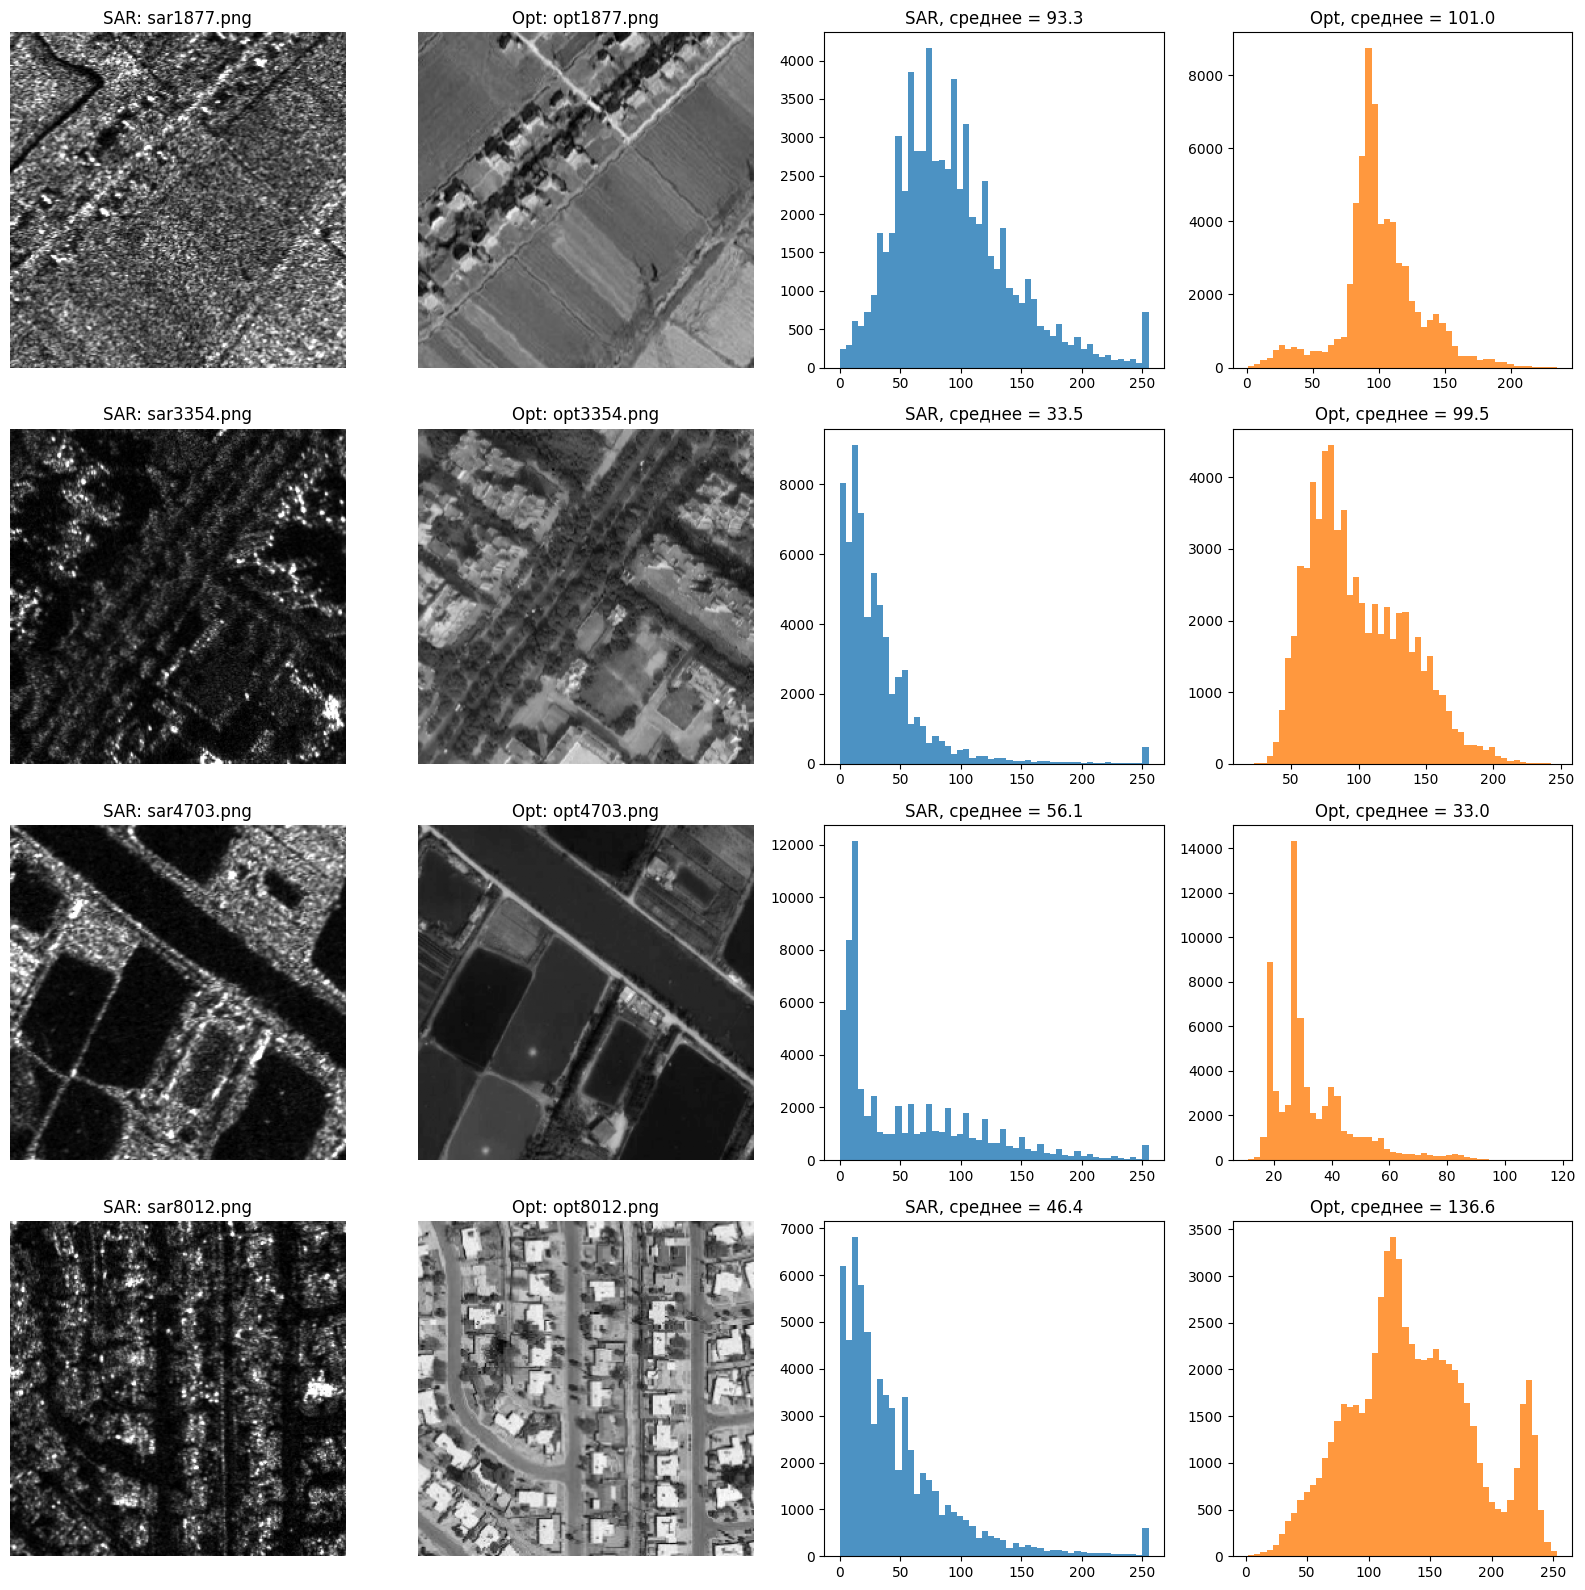

In [6]:
def visualize_pairs(pair_list, n_samples=4):
    chosen = random.sample(pair_list, n_samples)
    fig, axes = plt.subplots(n_samples, 4, figsize=(16, 4 * n_samples))
    for i, (sar_path, opt_path) in enumerate(chosen):
        sar = imread(sar_path, cv2.IMREAD_GRAYSCALE)
        opt = imread(opt_path, cv2.IMREAD_GRAYSCALE)
        axes[i, 0].imshow(sar, cmap="gray"); axes[i, 0].set_title("SAR: " + os.path.basename(sar_path)); axes[i, 0].axis("off")
        axes[i, 1].imshow(opt, cmap="gray"); axes[i, 1].set_title("Opt: " + os.path.basename(opt_path)); axes[i, 1].axis("off")
        axes[i, 2].hist(sar.ravel(), bins=50, color="tab:blue", alpha=0.8); axes[i, 2].set_title(f"SAR, среднее = {sar.mean():.1f}")
        axes[i, 3].hist(opt.ravel(), bins=50, color="tab:orange", alpha=0.8); axes[i, 3].set_title(f"Opt, среднее = {opt.mean():.1f}")
    plt.tight_layout()
    plt.show()


visualize_pairs(pairs["train"], n_samples=4)

In [7]:
def check_split_structure(data_root):
    for split in ["train", "val", "test"]:
        files = os.listdir(os.path.join(data_root, split))
        sar_ids = {natural_key(f) for f in files if f.startswith("sar")}
        opt_ids = {natural_key(f) for f in files if f.startswith("opt")}
        print(f"{split:5s}: SAR {len(sar_ids):5d} | Opt {len(opt_ids):5d} | пар {len(sar_ids & opt_ids):5d} | "
              f"SAR без пары {len(sar_ids - opt_ids)} | Opt без пары {len(opt_ids - sar_ids)}")


check_split_structure(DATA_PATH)

train: SAR  8044 | Opt  8044 | пар  8044 | SAR без пары 0 | Opt без пары 0
val  : SAR   952 | Opt   952 | пар   952 | SAR без пары 0 | Opt без пары 0
test : SAR  1696 | Opt  1696 | пар  1696 | SAR без пары 0 | Opt без пары 0


SAR: размеры (H, W[, C]) = [(256, 256)]
Opt: размеры (H, W[, C]) = [(256, 256)]


,среднее,ст. откл.,мин,макс
SAR mean,56.6,20.9,10.8,113.2
SAR std,44.6,9.0,12.9,75.9
SAR min,0.0,0.0,0.0,0.0
SAR max,254.7,4.7,189.0,255.0
Opt mean,82.0,33.8,20.6,175.3
Opt std,30.1,12.5,3.8,65.7
Opt min,11.7,18.0,0.0,94.0
Opt max,215.0,54.8,60.0,255.0


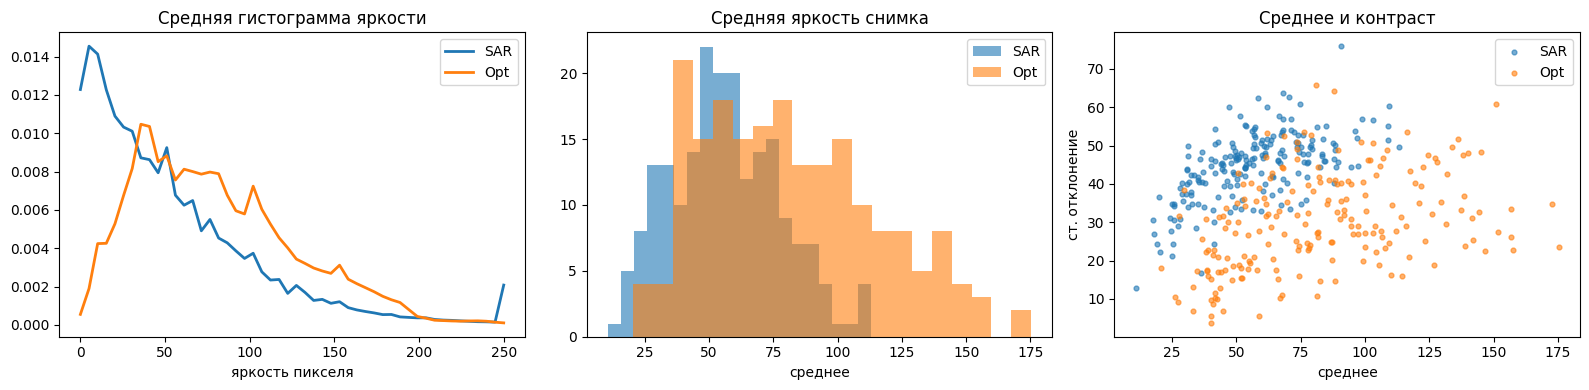

In [8]:
def pixel_statistics(pair_list, n_pairs=200):
    stats = {"SAR": {"mean": [], "std": [], "min": [], "max": []},
             "Opt": {"mean": [], "std": [], "min": [], "max": []}}
    shapes = {"SAR": set(), "Opt": set()}
    hists = {"SAR": [], "Opt": []}
    for sar_path, opt_path in random.sample(pair_list, n_pairs):
        for name, path in (("SAR", sar_path), ("Opt", opt_path)):
            img = imread(path, cv2.IMREAD_UNCHANGED)
            shapes[name].add(img.shape)
            for key, fn in (("mean", np.mean), ("std", np.std), ("min", np.min), ("max", np.max)):
                stats[name][key].append(float(fn(img)))
            hists[name].append(np.histogram(img.ravel(), bins=50, range=(0, 255), density=True)[0])

    for name in ("SAR", "Opt"):
        print(f"{name}: размеры (H, W[, C]) = {sorted(shapes[name])}")
    table = pd.DataFrame({f"{name} {key}": [np.mean(v), np.std(v), np.min(v), np.max(v)]
                          for name in stats for key, v in stats[name].items()},
                         index=["среднее", "ст. откл.", "мин", "макс"]).T.round(1)
    display(table)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    bins = np.linspace(0, 255, 51)[:-1]
    for name, color in (("SAR", "tab:blue"), ("Opt", "tab:orange")):
        axes[0].plot(bins, np.mean(hists[name], axis=0), color=color, lw=2, label=name)
        axes[1].hist(stats[name]["mean"], bins=20, alpha=0.6, color=color, label=name)
        axes[2].scatter(stats[name]["mean"], stats[name]["std"], s=12, alpha=0.6, color=color, label=name)
    axes[0].set_title("Средняя гистограмма яркости"); axes[0].set_xlabel("яркость пикселя")
    axes[1].set_title("Средняя яркость снимка"); axes[1].set_xlabel("среднее")
    axes[2].set_title("Среднее и контраст"); axes[2].set_xlabel("среднее"); axes[2].set_ylabel("ст. отклонение")
    for ax in axes:
        ax.legend()
    plt.tight_layout()
    plt.show()


pixel_statistics(pairs["train"], n_pairs=200)

**Вывод.** SAR заметно темнее оптики, и почти в каждом SAR-снимке есть и 0, и 255: авторы уже растянули контраст с насыщением ярких точек. Распределения яркости двух модальностей сильно различаются — поэтому нормализуем каждый снимок отдельно (InstanceNorm на входе сети).

Корреляция Пирсона внутри пар (200 пар): среднее +0.002, медиана +0.003, мин -0.653, макс +0.463


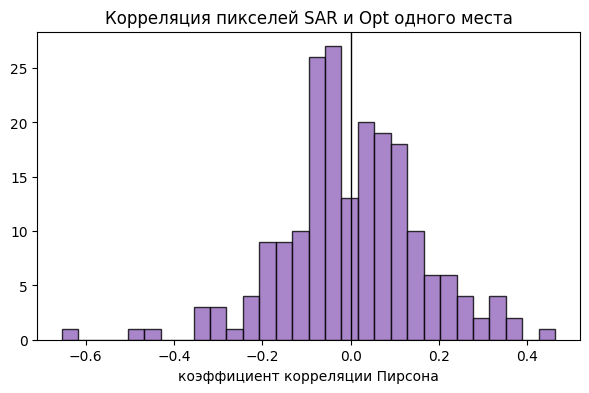

In [9]:
def pair_correlation(pair_list, n_pairs=200):
    corrs = []
    for sar_path, opt_path in random.sample(pair_list, n_pairs):
        sar = imread(sar_path, cv2.IMREAD_GRAYSCALE).astype(np.float32).ravel()
        opt = imread(opt_path, cv2.IMREAD_GRAYSCALE).astype(np.float32).ravel()
        corrs.append(np.corrcoef(sar, opt)[0, 1])
    corrs = np.array(corrs)
    print(f"Корреляция Пирсона внутри пар ({n_pairs} пар): среднее {corrs.mean():+.3f}, "
          f"медиана {np.median(corrs):+.3f}, мин {corrs.min():+.3f}, макс {corrs.max():+.3f}")
    plt.figure(figsize=(7, 4))
    plt.hist(corrs, bins=30, color="tab:purple", alpha=0.8, edgecolor="black")
    plt.axvline(0, color="black", lw=1)
    plt.title("Корреляция пикселей SAR и Opt одного места")
    plt.xlabel("коэффициент корреляции Пирсона")
    plt.show()
    return corrs


correlations = pair_correlation(pairs["train"], n_pairs=200)

**Вывод.** Корреляция пикселей внутри пар около нуля: снимки одного и того же места на уровне яркостей почти не похожи. Именно поэтому прямое сравнение пикселей (NCC) здесь не работает и нужна обученная метрика — сеть, которая находит общие для двух модальностей структурные признаки.

ENL по 150 однородным блокам: медиана 5.21, среднее 5.50


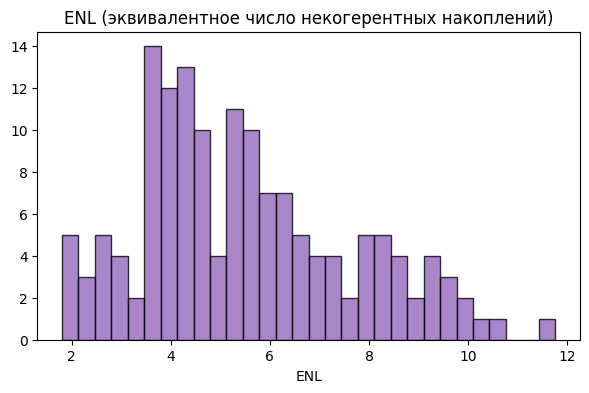

In [10]:
def estimate_enl(pair_list, n_images=50, block=32, n_candidates=30, keep=3):
    # ENL = mean^2 / var считается в ОДНОРОДНЫХ областях. Берём n_candidates случайных блоков
    # и оставляем keep блоков с минимальным коэффициентом вариации (самые однородные).
    enl = []
    for sar_path, _ in random.sample(pair_list, n_images):
        img = imread(sar_path, cv2.IMREAD_GRAYSCALE).astype(np.float64)
        h, w = img.shape
        cands = []
        for _ in range(n_candidates):
            y, x = np.random.randint(0, h - block), np.random.randint(0, w - block)
            b = img[y:y + block, x:x + block]
            m, v = b.mean(), b.var()
            if m > 5 and v > 0:
                cands.append((np.sqrt(v) / m, m * m / v))
        cands.sort()
        enl += [e for _, e in cands[:keep]]
    enl = np.array(enl)
    print(f"ENL по {len(enl)} однородным блокам: медиана {np.median(enl):.2f}, среднее {enl.mean():.2f}")
    plt.figure(figsize=(7, 4))
    plt.hist(enl, bins=30, color="tab:purple", alpha=0.8, edgecolor="black")
    plt.title("ENL (эквивалентное число некогерентных накоплений)")
    plt.xlabel("ENL")
    plt.show()
    return enl


enl_values = estimate_enl(pairs["train"])

**Вывод.** ENL порядка единиц — спекл выражен сильно (для однократного накопления ENL ≈ 1). Даже «однородные» блоки 32×32 часто захватывают края, поэтому значение — скорее оценка снизу.

## Модель

### Архитектура

**Сиамская сеть**: один и тот же `EmbeddingNet` (с общими весами) обрабатывает и SAR, и Opt.

`EmbeddingNet` переводит снимок 256×256 в вектор длины 1024:
- `InstanceNorm2d` — нормализация каждого снимка по его собственной статистике;
- 5 стадий по три свёртки 3×3 (Conv → BatchNorm → ReLU); первая свёртка стадии со `stride=2` уменьшает размер вдвое: 256 → 128 → 64 → 32 → 16 → 8;
- свёртка 8×8 сворачивает карту 8×8×512 в вектор 1×1×1024;
- `LocalResponseNorm` с такими параметрами делит вектор на его длину, то есть это **L2-нормировка**: все эмбеддинги лежат на единичной сфере, и расстояние между ними от 0 до 2.

> Псевдосиамский вариант (две ветки с **раздельными** весами для SAR и Opt) получается, если завести два экземпляра `EmbeddingNet`. Это будет частью ДЗ.

In [11]:
class Conv(nn.Module):
    # Conv -> BatchNorm -> ReLU
    def __init__(self, ch_in, ch_out, kernel, stride, act=True, bias=False):
        super().__init__()
        self.conv = nn.Conv2d(ch_in, ch_out, kernel, stride, padding=kernel // 2, bias=bias)
        self.bn = nn.BatchNorm2d(ch_out)
        self.act = nn.ReLU(inplace=True) if act else nn.Identity()

    def forward(self, x):
        return self.act(self.bn(self.conv(x)))


class EmbeddingNet(nn.Module):
    # Снимок 1x256x256 -> L2-нормированный вектор длины dim_desc
    def __init__(self, dim_desc=1024, drop_rate=0.5):
        super().__init__()
        self.dim_desc = dim_desc
        self.eps_l2_norm = 1e-10
        self.embede = nn.Sequential(
            nn.InstanceNorm2d(1, 1e-5),
            Conv(1, 32, 3, 2), Conv(32, 32, 3, 1), Conv(32, 32, 3, 1),           # 256 -> 128
            Conv(32, 64, 3, 2), Conv(64, 64, 3, 1), Conv(64, 64, 3, 1),          # 128 -> 64
            Conv(64, 128, 3, 2), Conv(128, 128, 3, 1), Conv(128, 128, 3, 1),     # 64 -> 32
            Conv(128, 256, 3, 2), Conv(256, 256, 3, 1), Conv(256, 256, 3, 1),    # 32 -> 16
            Conv(256, 512, 3, 2), Conv(512, 512, 3, 1), Conv(512, 512, 3, 1),    # 16 -> 8
            nn.Dropout(drop_rate),
            nn.Conv2d(512, dim_desc, 8, 1, bias=False),                          # 8x8 -> 1x1
            nn.BatchNorm2d(dim_desc),
        )
        # LRN с окном на все каналы и такими alpha/beta -> x / ||x||, то есть L2-нормировка
        self.desc_norm = nn.LocalResponseNorm(2 * dim_desc, alpha=2 * dim_desc, beta=0.5, k=0)

    def forward(self, x):
        descr = self.desc_norm(self.embede(x) + self.eps_l2_norm)
        return descr.view(-1, self.dim_desc)

### Triplet loss с самым трудным негативом в батче

Батч состоит из B пар (SAR_i, Opt_i). Для пары i:
- **позитив** — расстояние d(SAR_i, Opt_i);
- **негатив** — самое маленькое расстояние до *чужого* снимка в батче: среди d(SAR_i, Opt_j) и d(SAR_j, Opt_i) при j ≠ i (hard negative mining, как в HardNet).

Лосс штрафует пару, если чужой снимок ближе своего с запасом меньше margin:

L = (1/B) · Σ max(0, d_pos − d_neg + margin)²

Почему трудный негатив: случайный чужой снимок почти всегда и так далеко, лосс быстро зануляется и сеть перестаёт учиться. Обратите внимание: размер батча здесь — это ещё и число кандидатов в негативы.

In [12]:
class SiameseNet(nn.Module):
    def __init__(self, embedding_net):
        super().__init__()
        self.EmbeddingNet = embedding_net      # одна сеть на обе модальности = общие веса

    def get_embedding(self, x):
        return self.EmbeddingNet(x)

    def forward(self, sar, opt, margin=1.0):
        return self.loss(self.EmbeddingNet(sar), self.EmbeddingNet(opt), margin)

    @staticmethod
    def loss(sar_e, opt_e, margin=1.0):
        dist = torch.cdist(sar_e, opt_e)                                  # (B, B): d(SAR_i, Opt_j)
        d_pos = dist.diagonal()
        eye = torch.eye(dist.shape[0], dtype=torch.bool, device=dist.device)
        dist_neg = dist.masked_fill(eye, float("inf"))                    # исключаем свои пары
        d_neg = torch.minimum(dist_neg.min(dim=1).values,                 # SAR_i vs чужие Opt
                              dist_neg.min(dim=0).values)                 # Opt_i vs чужие SAR
        diff = F.relu(d_pos - d_neg + margin)
        return (diff ** 2).mean(), diff


model = SiameseNet(EmbeddingNet()).to(DEVICE)
print(f"Параметров: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M")

Параметров: 41.4 M


## Метрики

Функции метрик нужны и для контроля обучения, и для итоговой оценки, поэтому определяем их до обучения. Все считаются по матрице расстояний D размера N×N между эмбеддингами SAR (строки) и Opt (столбцы); правильная пара — на диагонали. Размер галереи N указываем всегда.

- **Recall@K** — доля SAR-запросов, у которых правильный Opt попал в K ближайших.
- **MRR** — среднее 1/ранг правильного Opt.
- **ROC-AUC** — вероятность того, что случайная истинная пара ближе случайной ложной; от порога не зависит.
- **FPR95** — доля ложных пар, принятых за истинные, при пороге, который находит 95% истинных пар.
- **Precision / Recall / F1** — при конкретном пороге «одно место / разные места». Порог выбираем **на валидации**, применяем на тесте.

In [13]:
@torch.no_grad()
def compute_embeddings(model, loader):
    model.eval()
    sar_list, opt_list = [], []
    for batch in tqdm(loader, desc="embeddings", leave=False):
        sar_list.append(model.get_embedding(batch["sar"].to(DEVICE)).cpu())
        opt_list.append(model.get_embedding(batch["opt"].to(DEVICE)).cpu())
    sar_emb = F.normalize(torch.cat(sar_list), dim=1).numpy()
    opt_emb = F.normalize(torch.cat(opt_list), dim=1).numpy()
    return sar_emb, opt_emb


def distance_matrix(sar_emb, opt_emb):
    # евклидово расстояние между единичными векторами: ||a - b||^2 = 2 - 2 <a, b>
    return np.sqrt(np.clip(2.0 - 2.0 * sar_emb @ opt_emb.T, 0.0, None))


def ranks_of_true_pairs(D):
    d_pos = np.diag(D)[:, None]
    return (D < d_pos).sum(axis=1) + 1          # 1 = правильный Opt ближе всех


def retrieval_metrics(D, ks=(1, 5, 10)):
    ranks = ranks_of_true_pairs(D)
    res = {f"Recall@{k}": float(np.mean(ranks <= k)) for k in ks}
    res["MRR"] = float(np.mean(1.0 / ranks))
    return res


def verification_metrics(D):
    y_true = np.eye(D.shape[0], dtype=np.uint8).ravel()
    scores = -D.ravel()                          # меньше расстояние -> больше уверенность «одно место»
    fpr, tpr, _ = roc_curve(y_true, scores)
    return {"ROC-AUC": float(roc_auc_score(y_true, scores)),
            "FPR95": float(fpr[np.searchsorted(tpr, 0.95)])}


def best_f1_threshold(D):
    # подбираем порог по F1 -- вызывать ТОЛЬКО на валидации
    y_true = np.eye(D.shape[0], dtype=np.uint8).ravel()
    precision, recall, thr = precision_recall_curve(y_true, -D.ravel())
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    return float(-thr[np.argmax(f1)])


def threshold_metrics(D, threshold):
    pred = D <= threshold
    true = np.eye(D.shape[0], dtype=bool)
    tp = np.sum(pred & true); fp = np.sum(pred & ~true); fn = np.sum(~pred & true)
    p = tp / max(tp + fp, 1); r = tp / max(tp + fn, 1)
    return {"Threshold": float(threshold), "Precision": float(p), "Recall": float(r),
            "F1": float(2 * p * r / max(p + r, 1e-12))}

## Обучение

- Первые `WARMUP_EPOCHS` эпох — разогрев с маленьким learning rate, затем `TRAIN_LR` с уменьшением вдвое каждые 20 эпох.
- После каждой эпохи считаем на валидации лосс, Recall@1 и MRR. Сохраняем веса **лучшей по Recall@1 на валидации** эпохи и историю обучения.

При `TRAIN_MODEL = False` обучение пропускается, а ниже строятся кривые из сохранённой истории обучения готовых весов.

In [14]:
def train_one_epoch(model, loader, optimizer, margin):
    model.train()
    total, n = 0.0, 0
    for batch in tqdm(loader, desc="train", leave=False):
        sar, opt = batch["sar"].to(DEVICE), batch["opt"].to(DEVICE)
        optimizer.zero_grad()
        loss, _ = model(sar, opt, margin=margin)
        loss.backward()
        optimizer.step()
        total += loss.item() * sar.shape[0]
        n += sar.shape[0]
    return total / n


@torch.no_grad()
def validate(model, loader, margin):
    model.eval()
    total, n = 0.0, 0
    for batch in loader:
        sar, opt = batch["sar"].to(DEVICE), batch["opt"].to(DEVICE)
        if sar.shape[0] < 2:
            continue
        loss, _ = model(sar, opt, margin=margin)
        total += loss.item() * sar.shape[0]
        n += sar.shape[0]
    res = retrieval_metrics(distance_matrix(*compute_embeddings(model, loader)), ks=(1,))
    return total / n, res["Recall@1"], res["MRR"]


def train(model):
    os.makedirs(WEIGHTS_DIR, exist_ok=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=WARMUP_LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=20, gamma=0.5)
    history, best_r1 = [], -1.0
    best_path = os.path.join(WEIGHTS_DIR, "best.pt")
    for epoch in range(1, TOTAL_EPOCHS + 1):
        if epoch == WARMUP_EPOCHS + 1:
            for group in optimizer.param_groups:
                group["lr"] = TRAIN_LR
        train_loss = train_one_epoch(model, train_loader, optimizer, MARGIN)
        if epoch > WARMUP_EPOCHS:
            scheduler.step()
        val_loss, val_r1, val_mrr = validate(model, val_loader, MARGIN)
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                        "val_recall@1": val_r1, "val_mrr": val_mrr})
        if val_r1 > best_r1:
            best_r1 = val_r1
            torch.save({"epoch": epoch, "model_state_dict": model.state_dict()}, best_path)
        print(f"epoch {epoch:3d} | train loss {train_loss:.3f} | val loss {val_loss:.3f} | "
              f"val R@1 {val_r1:.3f} | val MRR {val_mrr:.3f}")
    history = pd.DataFrame(history)
    history.to_csv(os.path.join(WEIGHTS_DIR, "history.csv"), index=False)
    print(f"Лучшая эпоха по val Recall@1: {int(history.loc[history['val_recall@1'].idxmax(), 'epoch'])} "
          f"(R@1 = {best_r1:.3f}), веса: {best_path}")
    return best_path, history


if TRAIN_MODEL:
    WEIGHTS_PATH, history = train(model)
    HISTORY_PATH = os.path.join(WEIGHTS_DIR, "history.csv")

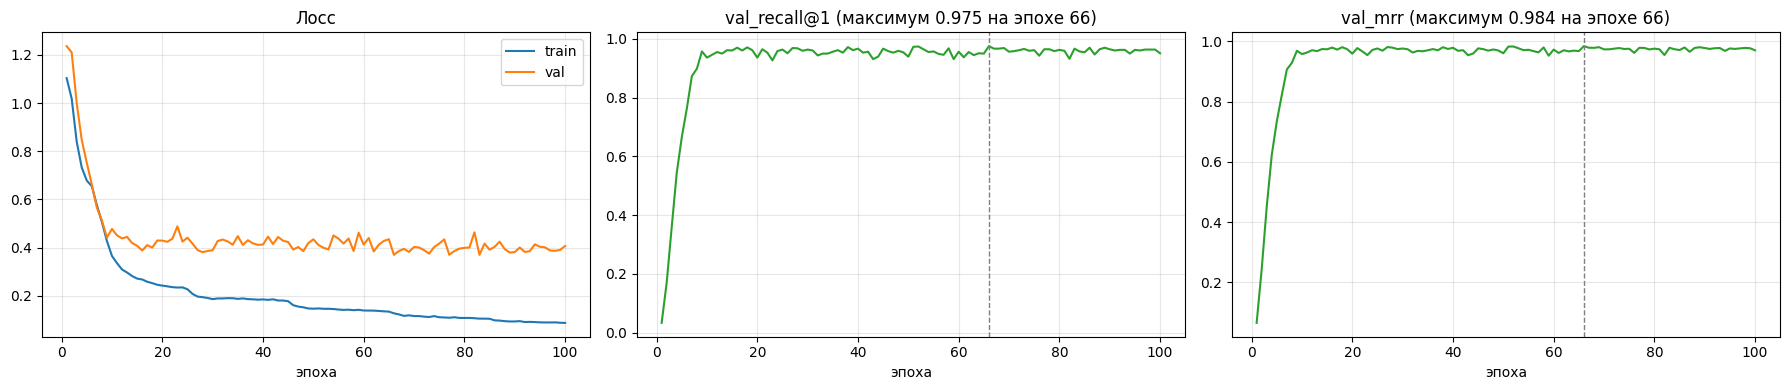

In [15]:
def plot_history(path):
    if not os.path.exists(path):
        print("Файл истории не найден:", path)
        return
    h = pd.read_csv(path)
    metric_cols = [c for c in h.columns if c.startswith("val_") and c != "val_loss"]
    fig, axes = plt.subplots(1, 1 + len(metric_cols), figsize=(6 * (1 + len(metric_cols)), 4))
    axes = np.atleast_1d(axes)
    axes[0].plot(h["epoch"], h["train_loss"], label="train")
    axes[0].plot(h["epoch"], h["val_loss"], label="val")
    axes[0].set_title("Лосс"); axes[0].set_xlabel("эпоха"); axes[0].legend(); axes[0].grid(alpha=0.3)
    for ax, col in zip(axes[1:], metric_cols):
        ax.plot(h["epoch"], h[col], color="tab:green")
        best = h.loc[h[col].idxmax()]
        ax.axvline(best["epoch"], color="gray", ls="--", lw=1)
        ax.set_title(f"{col} (максимум {best[col]:.3f} на эпохе {int(best['epoch'])})")
        ax.set_xlabel("эпоха"); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_history(HISTORY_PATH)

## Инференс

### Загрузка модели

Функция понимает и полный чекпоинт (с состоянием оптимизатора), и файл только с весами модели.

In [16]:
def load_model(path):
    checkpoint = torch.load(path, map_location=DEVICE, weights_only=False)
    state_dict = checkpoint.get("model_state_dict", checkpoint) if isinstance(checkpoint, dict) else checkpoint
    model = SiameseNet(EmbeddingNet())
    model.load_state_dict(state_dict)
    return model.to(DEVICE).float().eval()


model = load_model(WEIGHTS_PATH)
print("Загружены веса:", WEIGHTS_PATH)

Загружены веса: weights\best.pt


### Метрики на валидации и тесте

Сначала считаем эмбеддинги валидации и подбираем на ней порог для «одно место / разные места». На тесте этот порог только применяем.

In [17]:
val_sar, val_opt = compute_embeddings(model, val_loader)
test_sar, test_opt = compute_embeddings(model, test_loader)
D_val = distance_matrix(val_sar, val_opt)
D_test = distance_matrix(test_sar, test_opt)

threshold = best_f1_threshold(D_val)
print(f"Порог, выбранный на валидации по F1: {threshold:.4f}\n")

rows = {}
for name, D in (("val", D_val), ("test", D_test)):
    rows[f"{name} (N = {D.shape[0]})"] = {**retrieval_metrics(D), **verification_metrics(D), **threshold_metrics(D, threshold)}
results = pd.DataFrame(rows).round(4)
display(results)

embeddings:   0%|          | 0/15 [00:00<?, ?it/s]

embeddings:   0%|          | 0/27 [00:00<?, ?it/s]

Порог, выбранный на валидации по F1: 0.6744



,val (N = 952),test (N = 1696)
Recall@1,0.9748,0.9711
Recall@5,0.9947,0.9894
Recall@10,0.9979,0.9941
MRR,0.9842,0.9799
ROC-AUC,0.9988,0.9995
FPR95,0.0009,0.0004
Threshold,0.6744,0.6744
Precision,0.7935,0.7415
Recall,0.8435,0.9015
F1,0.8177,0.8137


Как читать таблицу:
- Случайный выбор дал бы Recall@1 = 1/N (для теста около 0.0006) — модель лучше на порядки.
- Precision / Recall / F1 считаются по всем N² парам, из которых истинных всего N. Поэтому даже небольшая доля ложных срабатываний заметно снижает Precision. Это ещё одна причина смотреть на ROC-AUC и FPR95.
- Порог подобран на валидации; если бы мы подбирали его на тесте, F1 на тесте вышел бы чуть выше — но это была бы утечка.

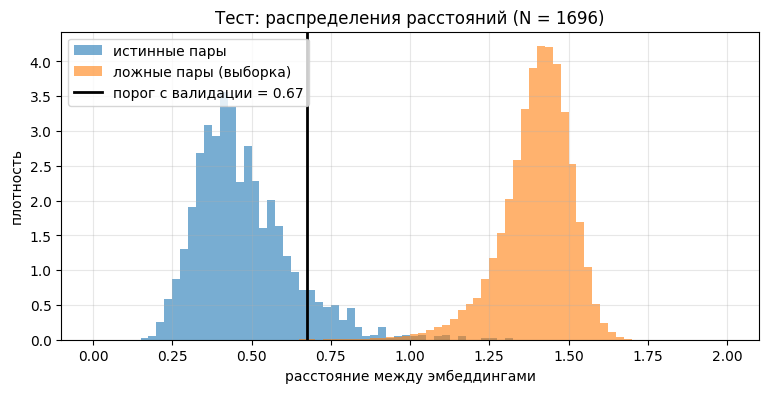

In [18]:
def plot_distance_distributions(D, threshold, title):
    pos = np.diag(D)
    neg = D[~np.eye(D.shape[0], dtype=bool)]
    neg = np.random.choice(neg, size=min(50_000, neg.size), replace=False)
    plt.figure(figsize=(9, 4))
    bins = np.linspace(0, 2, 81)
    plt.hist(pos, bins=bins, density=True, alpha=0.6, color="tab:blue", label="истинные пары")
    plt.hist(neg, bins=bins, density=True, alpha=0.6, color="tab:orange", label="ложные пары (выборка)")
    plt.axvline(threshold, color="black", lw=2, label=f"порог с валидации = {threshold:.2f}")
    plt.xlabel("расстояние между эмбеддингами"); plt.ylabel("плотность")
    plt.title(title); plt.legend(); plt.grid(alpha=0.3)
    plt.show()


plot_distance_distributions(D_test, threshold, f"Тест: распределения расстояний (N = {D_test.shape[0]})")

### Время работы

Меряем отдельно две вещи:
- **эмбеддинг** — сколько стоит прогнать один снимок через сеть (для GPU нужен прогрев и `torch.cuda.synchronize()`, иначе замер покажет только время постановки задачи в очередь);
- **поиск** — сколько стоит найти ближайшие Opt для всех SAR-запросов по готовым эмбеддингам.

In [19]:
@torch.no_grad()
def time_embedding(model, loader, n_batches=10, n_warmup=2):
    model.eval()
    batches = []
    for i, batch in enumerate(loader):
        batches.append(batch["sar"].to(DEVICE))
        if len(batches) >= n_batches + n_warmup:
            break
    for x in batches[:n_warmup]:
        model.get_embedding(x)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    n_images = 0
    for x in batches[n_warmup:]:
        model.get_embedding(x)
        n_images += x.shape[0]
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - t0) / n_images


emb_time = time_embedding(model, test_loader)
t0 = time.perf_counter()
_ = np.argsort(distance_matrix(test_sar, test_opt), axis=1)[:, :10]
search_time = time.perf_counter() - t0
print(f"Эмбеддинг: {emb_time * 1e3:.2f} мс на снимок (batch {BATCH_SIZE}, {DEVICE})")
print(f"Поиск top-10 для {len(test_sar)} запросов по галерее из {len(test_opt)}: {search_time * 1e3:.1f} мс "
      f"({search_time / len(test_sar) * 1e3:.3f} мс на запрос)")

Эмбеддинг: 1.07 мс на снимок (batch 64, cuda)
Поиск top-10 для 1696 запросов по галерее из 1696: 136.9 мс (0.081 мс на запрос)


Галерея эмбеддингов считается один раз заранее, поэтому для нового SAR-снимка цена поиска — один проход через сеть плюс сравнение с готовыми векторами. Сравнение растёт линейно с размером галереи; для миллионов снимков используют приближённый поиск ближайших соседей (например, FAISS).

## Разбор ошибок

### Что видит сеть по сравнению с пикселями

Возьмём 8 пар из теста и сравним две матрицы: корреляцию пикселей SAR_i и Opt_j и расстояние между их эмбеддингами. В идеале «своё» (диагональ) должно выделяться.

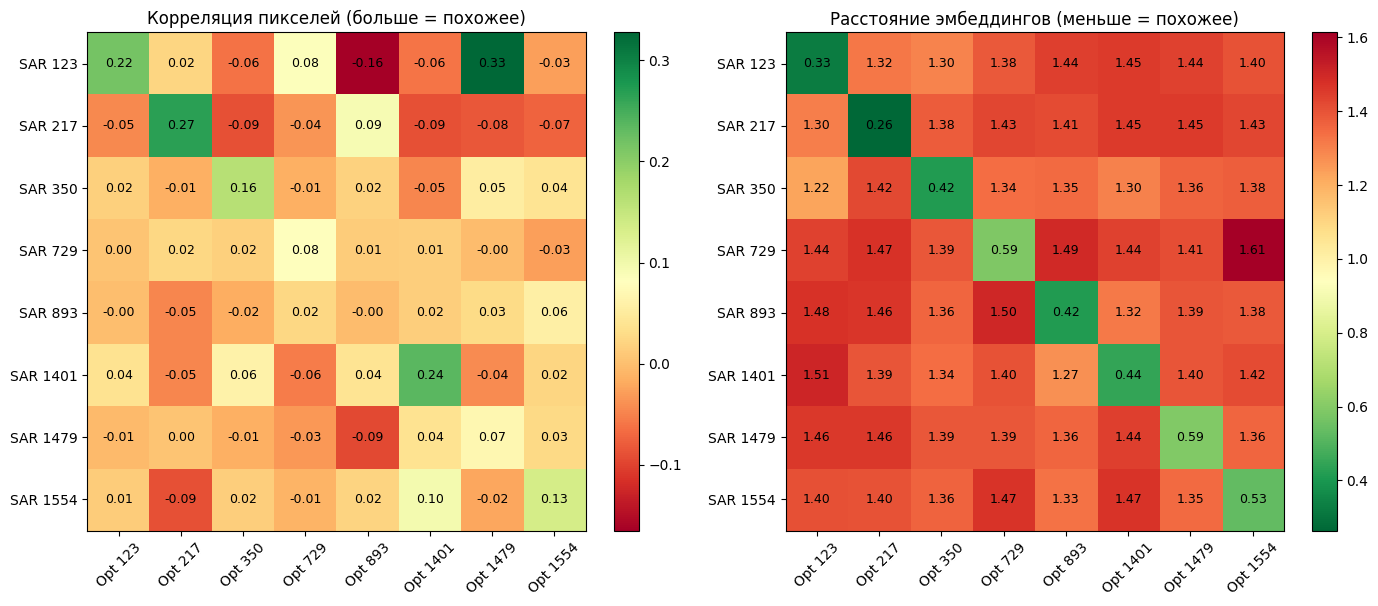

In [20]:
def compare_pixel_vs_embedding(pair_list, D, n=8):
    idx = sorted(random.sample(range(len(pair_list)), n))
    sars = [imread(pair_list[i][0], cv2.IMREAD_GRAYSCALE).astype(np.float32).ravel() for i in idx]
    opts = [imread(pair_list[i][1], cv2.IMREAD_GRAYSCALE).astype(np.float32).ravel() for i in idx]
    corr = np.array([[np.corrcoef(s, o)[0, 1] for o in opts] for s in sars])
    dist = D[np.ix_(idx, idx)]
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for ax, mat, title, cmap in ((axes[0], corr, "Корреляция пикселей (больше = похожее)", "RdYlGn"),
                                 (axes[1], dist, "Расстояние эмбеддингов (меньше = похожее)", "RdYlGn_r")):
        im = ax.imshow(mat, cmap=cmap)
        for i in range(n):
            for j in range(n):
                ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center", fontsize=9)
        ax.set_xticks(range(n)); ax.set_xticklabels([f"Opt {i}" for i in idx], rotation=45)
        ax.set_yticks(range(n)); ax.set_yticklabels([f"SAR {i}" for i in idx])
        ax.set_title(title)
        plt.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    plt.show()


compare_pixel_vs_embedding(pairs["test"], D_test)

**Вывод.** По пикселям диагональ выделяется не сильно — корреляция «своих» пар примерно такая же, как у чужих. В пространстве эмбеддингов свои пары заметно ближе: сеть выучила признаки, общие для двух модальностей.

### Примеры удачного и неудачного поиска

Для SAR-запроса показываем 5 ближайших Opt из галереи. Зелёная рамка — правильный снимок.

Верно найдено (ранг 1): 1647 из 1696; ошибок: 49


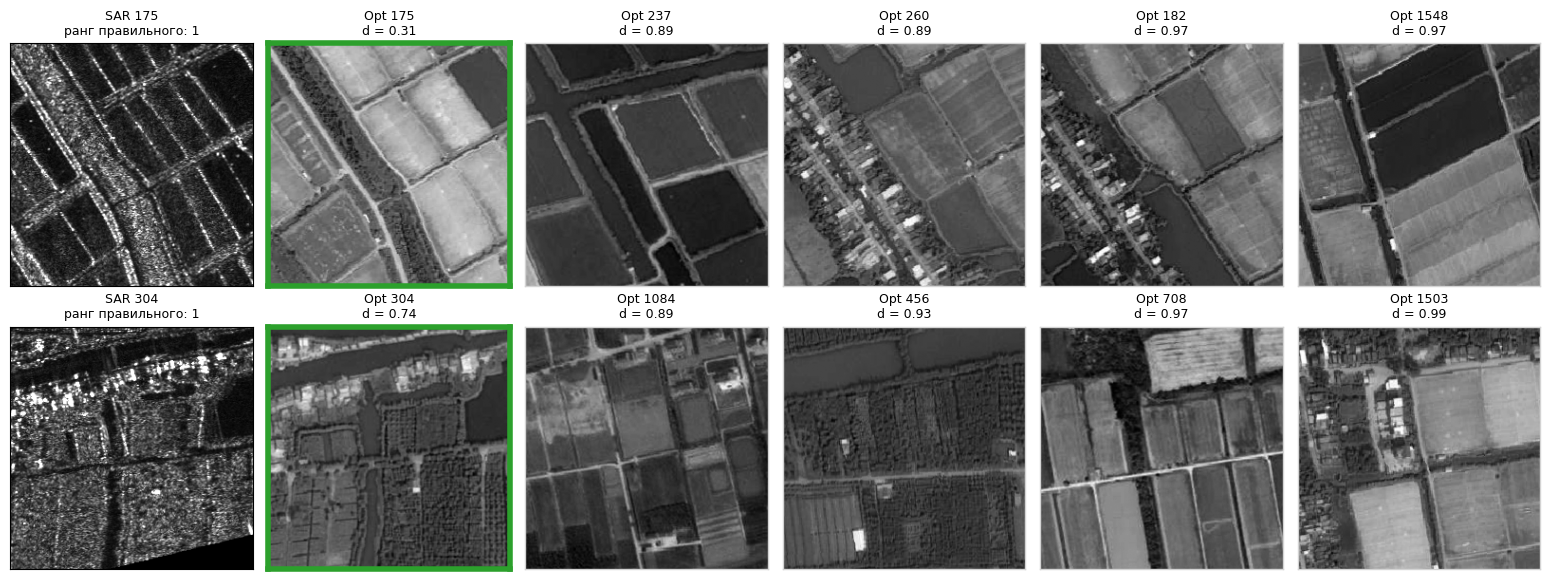

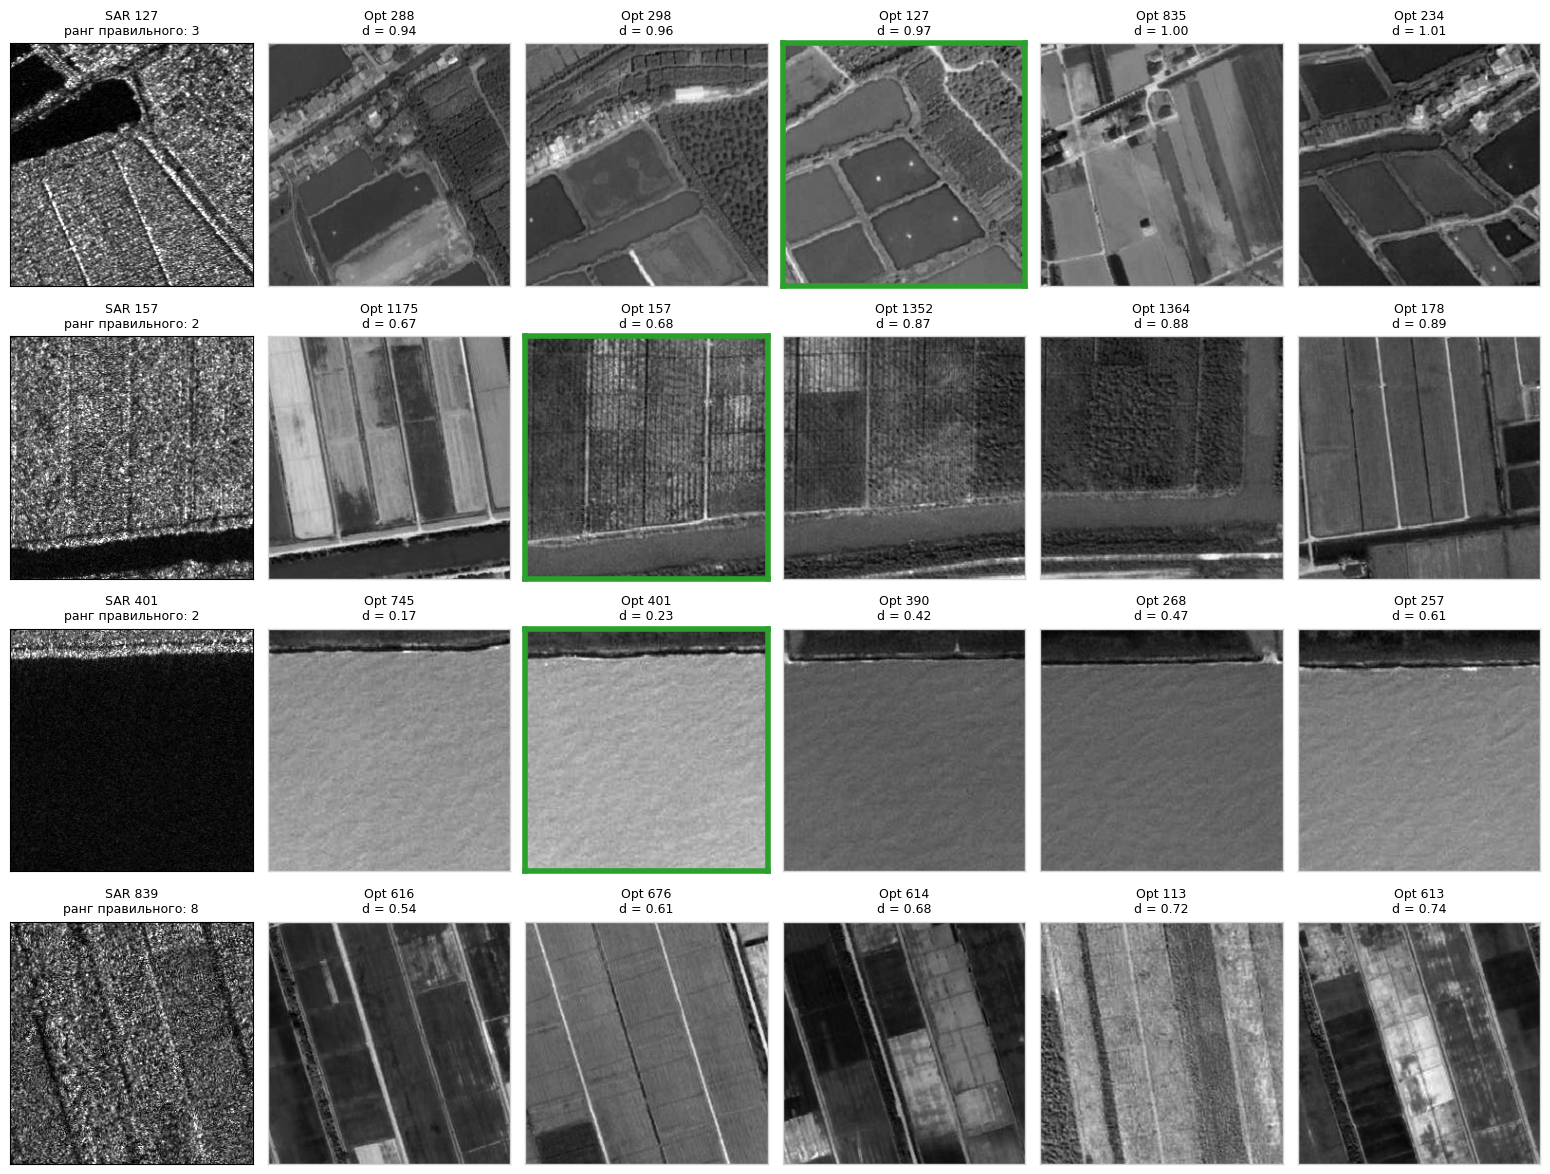

In [42]:
def show_retrieval(pair_list, D, query_ids, top_k=5):
    fig, axes = plt.subplots(len(query_ids), top_k + 1, figsize=(2.6 * (top_k + 1), 3.0 * len(query_ids)))
    axes = np.atleast_2d(axes)
    ranks = ranks_of_true_pairs(D)
    for row, q in enumerate(query_ids):
        axes[row, 0].imshow(imread(pair_list[q][0], cv2.IMREAD_GRAYSCALE), cmap="gray")
        axes[row, 0].set_title(f"SAR {q}\nранг правильного: {ranks[q]}", fontsize=9)
        for j, g in enumerate(np.argsort(D[q])[:top_k]):
            ax = axes[row, j + 1]
            ax.imshow(imread(pair_list[g][1], cv2.IMREAD_GRAYSCALE), cmap="gray")
            ax.set_title(f"Opt {g}\nd = {D[q, g]:.2f}", fontsize=9)
            for spine in ax.spines.values():
                spine.set_edgecolor("tab:green" if g == q else "lightgray")
                spine.set_linewidth(4 if g == q else 1)
        for ax in axes[row]:
            ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout()
    plt.show()


test_ranks = ranks_of_true_pairs(D_test)
correct_ids = np.where(test_ranks == 1)[0]
wrong_ids = np.where(test_ranks > 1)[0]
print(f"Верно найдено (ранг 1): {len(correct_ids)} из {len(test_ranks)}; ошибок: {len(wrong_ids)}")
show_retrieval(pairs["test"], D_test, list(np.random.choice(correct_ids, 2, replace=False)))
show_retrieval(pairs["test"], D_test, list(np.random.choice(wrong_ids, min(4, len(wrong_ids)), replace=False)))

**На что обратить внимание в ошибках:** обычно путаются однородные сцены (поля, вода, лес) и похожие кварталы. Часто ближайшим оказывается **соседний фрагмент той же сцены** — это и есть те «почти одинаковые» снимки, на которых модель ошибается. Часть ошибок объясняется этим

### Проверка: одно и то же это место или нет

Режим верификации: на вход одна пара, на выходе ответ «одно место / разные места» по порогу, выбранному на валидации.

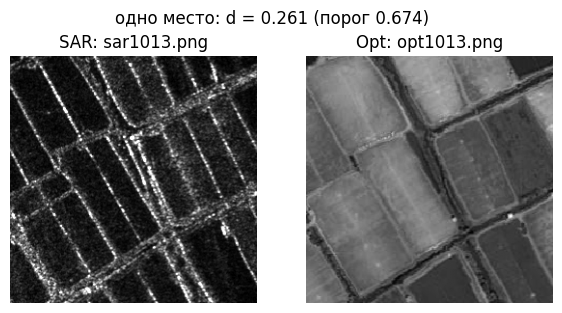

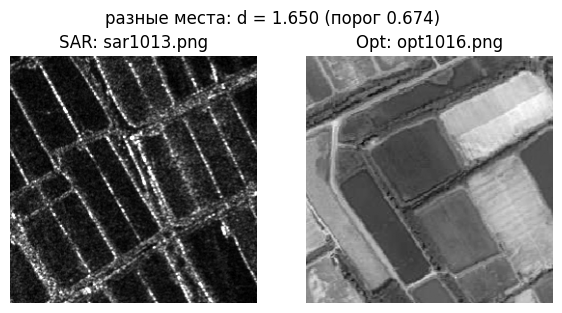

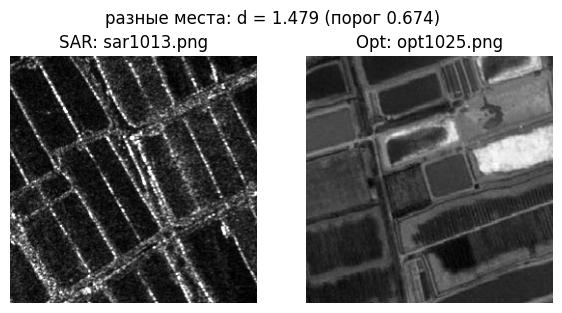

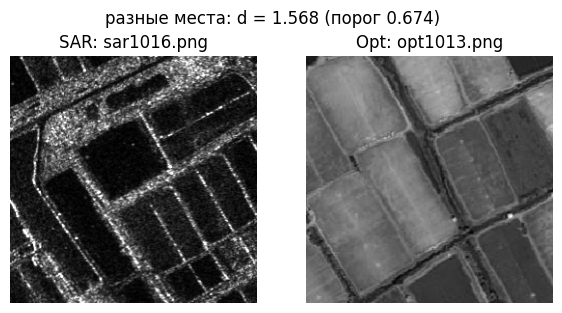

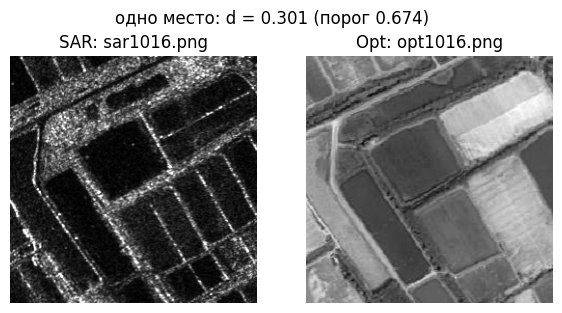

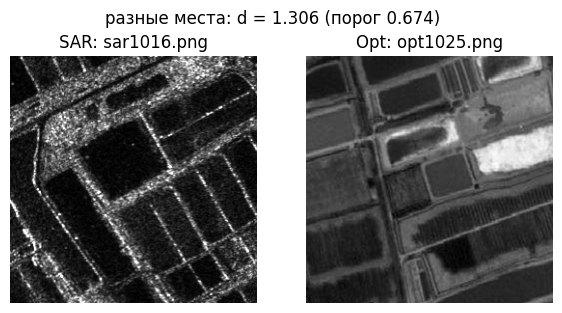

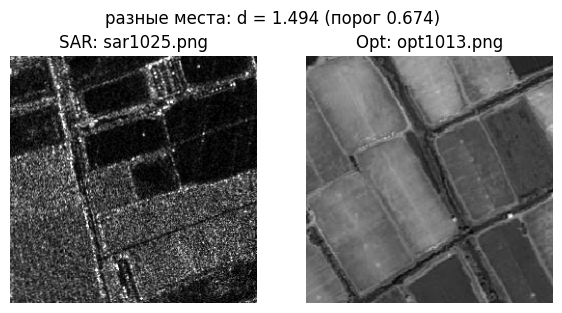

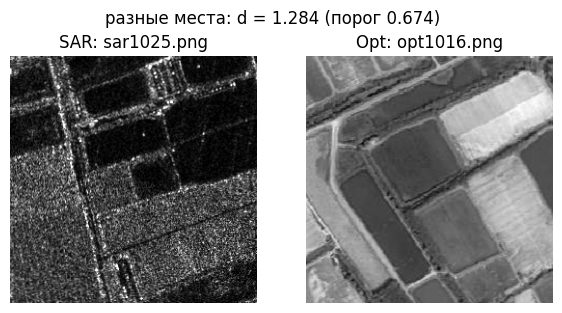

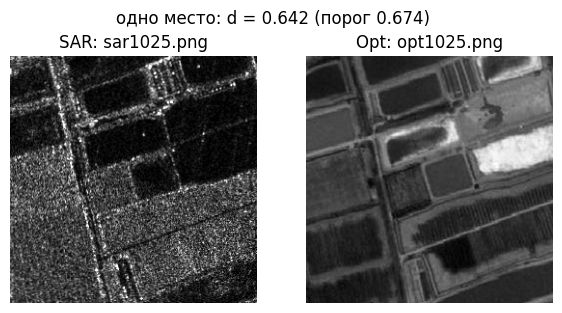

In [22]:
@torch.no_grad()
def is_same_place(model, sar_path, opt_path, threshold, show=True):
    sar = imread(sar_path, cv2.IMREAD_GRAYSCALE)
    opt = imread(opt_path, cv2.IMREAD_GRAYSCALE)
    to_tensor = lambda img: torch.from_numpy(img[np.newaxis, np.newaxis].astype(np.float32)).to(DEVICE)
    sar_e = F.normalize(model.get_embedding(to_tensor(sar)), dim=1)
    opt_e = F.normalize(model.get_embedding(to_tensor(opt)), dim=1)
    dist = torch.dist(sar_e, opt_e).item()
    same = dist <= threshold
    if show:
        fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
        axes[0].imshow(sar, cmap="gray"); axes[0].set_title("SAR: " + os.path.basename(sar_path))
        axes[1].imshow(opt, cmap="gray"); axes[1].set_title("Opt: " + os.path.basename(opt_path))
        for ax in axes:
            ax.axis("off")
        verdict = "одно место" if same else "разные места"
        fig.suptitle(f"{verdict}: d = {dist:.3f} (порог {threshold:.3f})")
        plt.show()
    return same, dist


for i, j in product([17, 20, 30], repeat=2):
    is_same_place(model, pairs["test"][i][0], pairs["test"][j][1], threshold)

## Проверка на другом датасете: QXS-SAROPT

Модель обучена на OS dataset. Посмотрим, что будет на [QXS-SAROPT](https://github.com/yaoxu008/QXS-SAROPT) — это тоже Gaofen-3 + Google Earth, но другие города (Сан-Диего, Шанхай, Циндао). Берём 1000 случайных пар из его валидационной части и считаем те же метрики **без дообучения**. На этом датасете будет ДЗ 1.

Ячейка пропускается, если папки с QXS-SAROPT нет.

embeddings:   0%|          | 0/16 [00:00<?, ?it/s]

,OS test (N = 1000),QXS-SAROPT (N = 1000)
Recall@1,0.9760,0.3910
Recall@5,0.9930,0.5280
Recall@10,0.9950,0.5810
MRR,0.9840,0.4596
ROC-AUC,0.9998,0.9184
FPR95,0.0005,0.4409


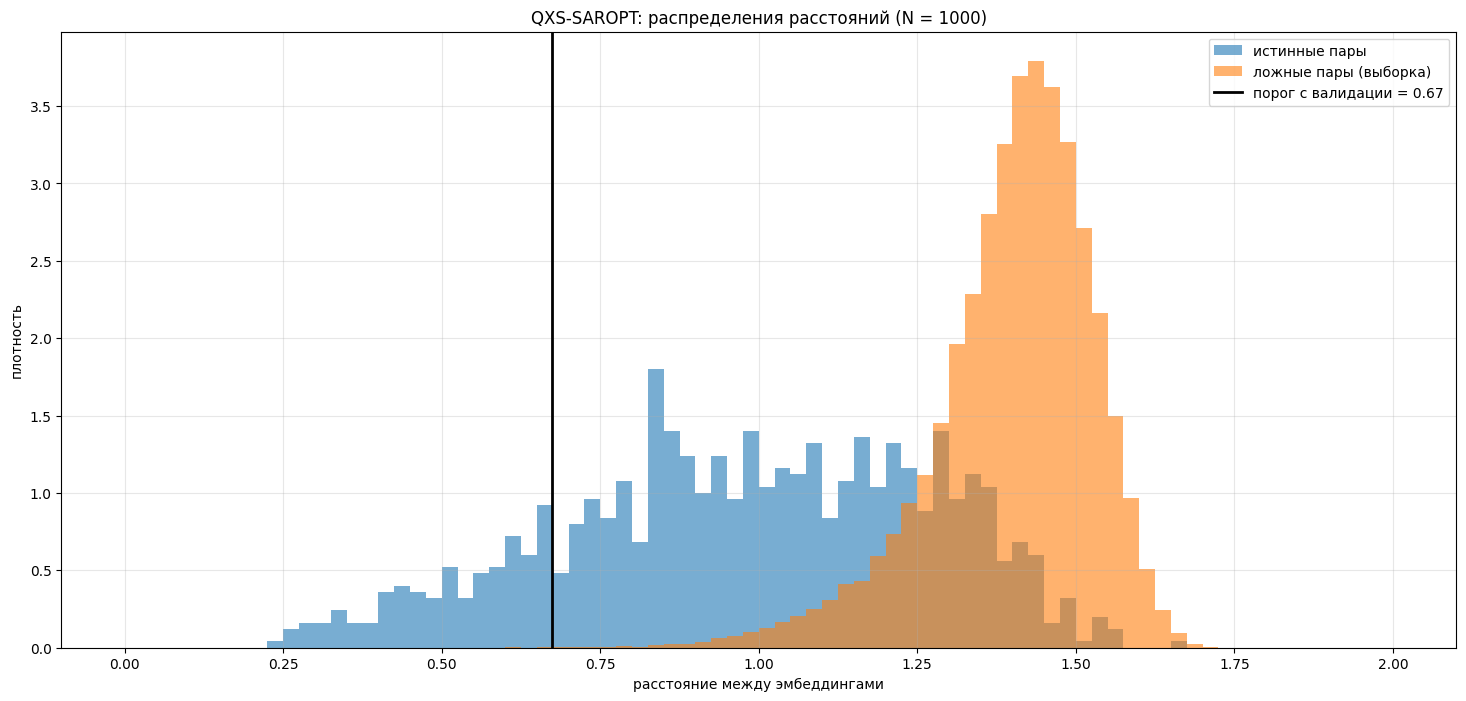

In [48]:
def qxs_pairs(root, split="val", n=1000):
    # формат как у OS dataset: <root>/<split>/sar<n>.png и opt<n>.png
    folder = os.path.join(root, split)
    sar_names = sorted([f for f in os.listdir(folder) if f.startswith("sar")], key=natural_key)
    names = [x for x in sar_names if os.path.exists(os.path.join(folder, "opt" + x[len("sar"):]))]
    chosen = random.Random(SEED).sample(names, min(n, len(names)))
    return [(os.path.join(folder, x), os.path.join(folder, "opt" + x[len("sar"):])) for x in chosen]


if os.path.isdir(os.path.join(QXS_PATH, "val")):
    qxs = qxs_pairs(QXS_PATH, "val", n=1000)
    qxs_loader = DataLoader(SarOptDataset(qxs), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    D_qxs = distance_matrix(*compute_embeddings(model, qxs_loader))
    D_test_1000 = D_test[:1000, :1000]   # та же размерность галереи для честного сравнения
    comparison = pd.DataFrame({
        "OS test (N = 1000)": {**retrieval_metrics(D_test_1000), **verification_metrics(D_test_1000)},
        "QXS-SAROPT (N = 1000)": {**retrieval_metrics(D_qxs), **verification_metrics(D_qxs)},
    }).round(4)
    display(comparison)
    plot_distance_distributions(D_qxs, threshold, "QXS-SAROPT: распределения расстояний (N = 1000)")
else:
    print("Папка QXS-SAROPT не найдена:", QXS_PATH, "-- пропускаем")

**Вывод.** На новом датасете метрики заметно хуже, чем на тесте OS dataset, хотя тип данных тот же. Две причины: смена домена (другие города, застройка, условия съёмки) и, вероятно, завышенные метрики на OS из-за соседних фрагментов одной сцены в train и test. Порог, подобранный на OS, на новом датасете тоже уже не оптимален — распределения расстояний сдвинулись.

Отсюда задачи ДЗ 1: псевдосиамская сеть, свой лосс и дообучение на QXS-SAROPT с честным разбиением.

## Итоги

- Корреляция пикселей SAR и Opt одного места около нуля — прямое сравнение не работает, нужна обученная метрика.
- Сиамская сеть с triplet loss и трудными негативами из батча строит пространство, где свои пары ближе чужих.
- Качество поиска описываем Recall@K и MRR (с размером галереи), верификацию — ROC-AUC и FPR95; порог выбираем на валидации.
- Высокие метрики на одном датасете не гарантируют такого же качества на другом: проверка на QXS-SAROPT это показывает.